# Fase C — Modelos predictivos y segmentación
**Proyecto 2 y 3 — Estadísticas delictivas de Colombia 2025 (DIJIN)** · Grupo 7 · R.A. 2 y 3

## Pregunta de negocio
**¿Cuántos casos delictivos registrará cada municipio el mes siguiente?** Saberlo con anticipación permite
asignar patrullaje, fiscales e investigadores donde se necesitarán. Es la "proyección de casos por mes" que
dejó planteada el Proyecto 1.

* **Tipo de problema:** regresión (variable objetivo continua: casos del mes, `casos`).
* **Modelos supervisados (3):** Regresión Lineal, Random Forest Regressor y Gradient Boosting Regressor.
* **Referencia obligatoria:** una **regla ingenua** ("el mes que viene = este mes"). Un modelo solo vale la pena si la supera.
* **No supervisado (1):** K-Means para segmentar municipios por perfil delictivo (Silhouette y Davies-Bouldin).

**Diseño del objetivo:** los modelos no predicen el nivel de casos directamente sino **la variación (en escala log)
respecto al mes anterior**; la predicción final es `log1p(mes anterior) + variación predicha`. La sección 3 muestra por qué.

**Cómo se evitó la fuga de información (data leakage):**
1. La partición 80/20 se hizo en la Fase B **antes** de calcular medianas, vecinos KNN o escalas; aquí se verifica que
   coincide con `train_test_split(random_state=42)`.
2. Las variables del modelo son solo del **mes anterior o acumuladas hasta él**, nunca del mes que se predice.
3. Se excluye `atipico_iqr` (se calculó con el valor del mes objetivo: usarla sería hacer trampa) y `casos`.
4. Todo se evalúa **solo con el conjunto de prueba**, que no se tocó durante el entrenamiento ni el ajuste de hiperparámetros.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import davies_bouldin_score, mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "entrega" else Path.cwd()
CARPETA_FIGURAS = RAIZ / "figuras"
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
SEMILLA = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format

## 1. Carga y partición

In [2]:
zanahoria_2026_df_limpio = pd.read_parquet(RAIZ / "entrega" / "datos_limpios.parquet")
print("Datos limpios:", zanahoria_2026_df_limpio.shape)

# Columnas que NO pueden ser variables del modelo: identificadores, el objetivo y todo lo derivado de él
NO_FEATURES = ["dane", "departamento", "municipio", "mes", "particion", "atipico_iqr", "casos", "y_log1p", "casos_lag1_ref"]
FEATURES = [c for c in zanahoria_2026_df_limpio.columns if c not in NO_FEATURES]
assert not {"casos", "y_log1p", "atipico_iqr"} & set(FEATURES), "fuga: una variable del objetivo entró a las features"
print(f"Variables explicativas: {len(FEATURES)}")

# La partición de la Fase B debe ser exactamente la de train_test_split con la misma semilla
idx_train, idx_test = train_test_split(zanahoria_2026_df_limpio.index, test_size=0.20, random_state=SEMILLA)
assert set(idx_train) == set(zanahoria_2026_df_limpio.index[zanahoria_2026_df_limpio["particion"] == "train"])
print(f"Entrenamiento: {len(idx_train):,} filas | Prueba: {len(idx_test):,} filas (80/20)")

Datos limpios: (16500, 59)
Variables explicativas: 50
Entrenamiento: 13,200 filas | Prueba: 3,300 filas (80/20)


In [3]:
X_train, X_test = zanahoria_2026_df_limpio.loc[idx_train, FEATURES], zanahoria_2026_df_limpio.loc[idx_test, FEATURES]
y_train, y_test = zanahoria_2026_df_limpio.loc[idx_train, "y_log1p"], zanahoria_2026_df_limpio.loc[idx_test, "y_log1p"]
casos_test = zanahoria_2026_df_limpio.loc[idx_test, "casos"]          # objetivo en escala original
lag_test = zanahoria_2026_df_limpio.loc[idx_test, "casos_lag1_ref"]   # casos del mes anterior (regla ingenua)

# Punto de partida de cada predicción: el nivel del mes anterior (en log). Es información disponible al predecir.
base_train = np.log1p(zanahoria_2026_df_limpio.loc[idx_train, "casos_lag1_ref"])
base_test = np.log1p(lag_test)
delta_train = y_train - base_train      # lo que realmente aprende el modelo: cuánto cambia el municipio respecto al mes anterior

# Las variables ya vienen escaladas con estadísticos de entrenamiento (Fase B); el objetivo se modela en log1p
# y las métricas se reportan en las dos escalas: log (todos los municipios pesan parecido) y original (pesan las ciudades grandes).
print(X_train.shape, X_test.shape)

(13200, 50) (3300, 50)


## 2. Métricas y regla ingenua de referencia

In [4]:
def zanahoria_2026_metricas(real_log: pd.Series, pred_log: np.ndarray, nombre: str) -> dict:
    """ZANAHORIA_2026: calcula MSE, RMSE, R2 y MAE en escala log y en escala original (casos)."""
    pred_log = np.asarray(pred_log)
    real = np.expm1(real_log)
    pred = np.clip(np.expm1(pred_log), 0, None)           # no existen casos negativos
    mse_o = mean_squared_error(real, pred)
    mse_l = mean_squared_error(real_log, pred_log)
    return {
        "modelo": nombre,
        "R² (log)": r2_score(real_log, pred_log), "RMSE (log)": np.sqrt(mse_l), "MAE (log)": mean_absolute_error(real_log, pred_log), "MSE (log)": mse_l,
        "R² (casos)": r2_score(real, pred), "RMSE (casos)": np.sqrt(mse_o), "MAE (casos)": mean_absolute_error(real, pred), "MSE (casos)": mse_o,
    }

# Regla ingenua: "los casos de este mes serán iguales a los del mes anterior"
pred_ingenua_log = np.log1p(lag_test.values)
resultados = [zanahoria_2026_metricas(y_test, pred_ingenua_log, "Regla ingenua (mes anterior)")]
pd.DataFrame(resultados).set_index("modelo")

,R² (log),RMSE (log),MAE (log),MSE (log),R² (casos),RMSE (casos),MAE (casos),MSE (casos)
modelo,,,,,,,,
Regla ingenua (mes anterior),0.797,0.613,0.409,0.375,0.983,85.150,6.953,"7,250.498"


## 3. Decisión de diseño: ¿predecir el nivel o la variación?
Un Random Forest promedia valores que vio en entrenamiento, así que **no puede predecir más allá de lo
que ya vio**: con pocos municipios de miles de casos (Bogotá, Medellín, Cali) esto es un problema.
Se compara, con los mismos hiperparámetros, predecir el nivel directamente o predecir la variación respecto al mes anterior.

In [5]:
rf_prueba = dict(n_estimators=150, max_depth=12, min_samples_leaf=6, max_features=0.5, random_state=SEMILLA, n_jobs=-1)
directo = RandomForestRegressor(**rf_prueba).fit(X_train, y_train).predict(X_test)
variacion = base_test.values + RandomForestRegressor(**rf_prueba).fit(X_train, delta_train).predict(X_test)
zanahoria_2026_df_diseno = pd.DataFrame([
    zanahoria_2026_metricas(y_test, directo, "RF — objetivo: nivel"),
    zanahoria_2026_metricas(y_test, variacion, "RF — objetivo: variación"),
]).set_index("modelo")[["R² (log)", "MAE (log)", "R² (casos)", "RMSE (casos)", "MAE (casos)"]]
zanahoria_2026_df_diseno

,R² (log),MAE (log),R² (casos),RMSE (casos),MAE (casos)
modelo,,,,,
RF — objetivo: nivel,0.871,0.375,0.681,370.787,17.870
RF — objetivo: variación,0.869,0.377,0.971,112.548,7.870


**Decisión:** predecir la **variación**. Con el nivel directo el Random Forest se desploma en escala de casos
(R² 0,68) porque no llega a las magnitudes de las capitales; con la variación parte de la regla ingenua
y solo aprende la corrección, así que conserva el nivel de las ciudades grandes (R² 0,97).
Para la Regresión Lineal es equivalente (el mes anterior ya es una variable); se aplica igual por consistencia.

## 4. Modelo 1 — Regresión Lineal
Es el modelo más simple e interpretable. No tiene hiperparámetros que ajustar.

In [6]:
modelo_lineal = LinearRegression().fit(X_train, delta_train)
pred_lineal = base_test.values + modelo_lineal.predict(X_test)
resultados.append(zanahoria_2026_metricas(y_test, pred_lineal, "Regresión Lineal"))
print("R² entrenamiento:", round(r2_score(y_train, base_train.values + modelo_lineal.predict(X_train)), 3), "| R² prueba:", round(r2_score(y_test, pred_lineal), 3))

R² entrenamiento: 0.86 | R² prueba: 0.869


## 5. Modelo 2 — Random Forest Regressor
Se ajustan los hiperparámetros con **búsqueda aleatoria y validación cruzada de 3 pliegues solo sobre el
conjunto de entrenamiento**; el conjunto de prueba no interviene.

In [7]:
busqueda_rf = RandomizedSearchCV(
    RandomForestRegressor(random_state=SEMILLA, n_jobs=-1),
    param_distributions={"n_estimators": [150, 250], "max_depth": [8, 12, 16, None], "min_samples_leaf": [1, 3, 6], "max_features": [0.3, 0.5, 1.0]},
    n_iter=6, cv=3, scoring="neg_mean_squared_error", random_state=SEMILLA, n_jobs=1,
)
busqueda_rf.fit(X_train, delta_train)
modelo_rf = busqueda_rf.best_estimator_
pred_rf = base_test.values + modelo_rf.predict(X_test)
resultados.append(zanahoria_2026_metricas(y_test, pred_rf, "Random Forest"))
print("Mejores hiperparámetros:", busqueda_rf.best_params_)
print("R² entrenamiento:", round(r2_score(y_train, base_train.values + modelo_rf.predict(X_train)), 3), "| R² prueba:", round(r2_score(y_test, pred_rf), 3))

Mejores hiperparámetros: {'n_estimators': 150, 'min_samples_leaf': 6, 'max_features': 0.5, 'max_depth': 12}
R² entrenamiento: 0.896 | R² prueba: 0.869


## 6. Modelo 3 — Gradient Boosting Regressor

In [8]:
busqueda_gb = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=SEMILLA),
    param_distributions={"n_estimators": [150, 300], "learning_rate": [0.05, 0.1], "max_depth": [2, 3, 4], "subsample": [0.8, 1.0], "min_samples_leaf": [1, 5]},
    n_iter=6, cv=3, scoring="neg_mean_squared_error", random_state=SEMILLA, n_jobs=1,
)
busqueda_gb.fit(X_train, delta_train)
modelo_gb = busqueda_gb.best_estimator_
pred_gb = base_test.values + modelo_gb.predict(X_test)
resultados.append(zanahoria_2026_metricas(y_test, pred_gb, "Gradient Boosting"))
print("Mejores hiperparámetros:", busqueda_gb.best_params_)
print("R² entrenamiento:", round(r2_score(y_train, base_train.values + modelo_gb.predict(X_train)), 3), "| R² prueba:", round(r2_score(y_test, pred_gb), 3))

Mejores hiperparámetros: {'subsample': 1.0, 'n_estimators': 300, 'min_samples_leaf': 1, 'max_depth': 2, 'learning_rate': 0.1}
R² entrenamiento: 0.868 | R² prueba: 0.87


## 7. Comparación de los modelos (conjunto de prueba)

In [9]:
zanahoria_2026_df_metricas = pd.DataFrame(resultados).set_index("modelo")
print("Escala log (todos los municipios pesan parecido):")
display(zanahoria_2026_df_metricas[["R² (log)", "RMSE (log)", "MAE (log)", "MSE (log)"]])
print("Escala original, en casos por mes (dominan las ciudades grandes):")
display(zanahoria_2026_df_metricas[["R² (casos)", "RMSE (casos)", "MAE (casos)", "MSE (casos)"]])

Escala log (todos los municipios pesan parecido):


,R² (log),RMSE (log),MAE (log),MSE (log)
modelo,,,,
Regla ingenua (mes anterior),0.797,0.613,0.409,0.375
Regresión Lineal,0.869,0.493,0.377,0.243
Random Forest,0.869,0.492,0.377,0.242
Gradient Boosting,0.870,0.489,0.375,0.240


Escala original, en casos por mes (dominan las ciudades grandes):


,R² (casos),RMSE (casos),MAE (casos),MSE (casos)
modelo,,,,
Regla ingenua (mes anterior),0.983,85.150,6.953,"7,250.498"
Regresión Lineal,0.949,148.449,8.756,"22,037.119"
Random Forest,0.971,112.548,7.870,"12,666.991"
Gradient Boosting,0.986,78.501,6.454,"6,162.456"


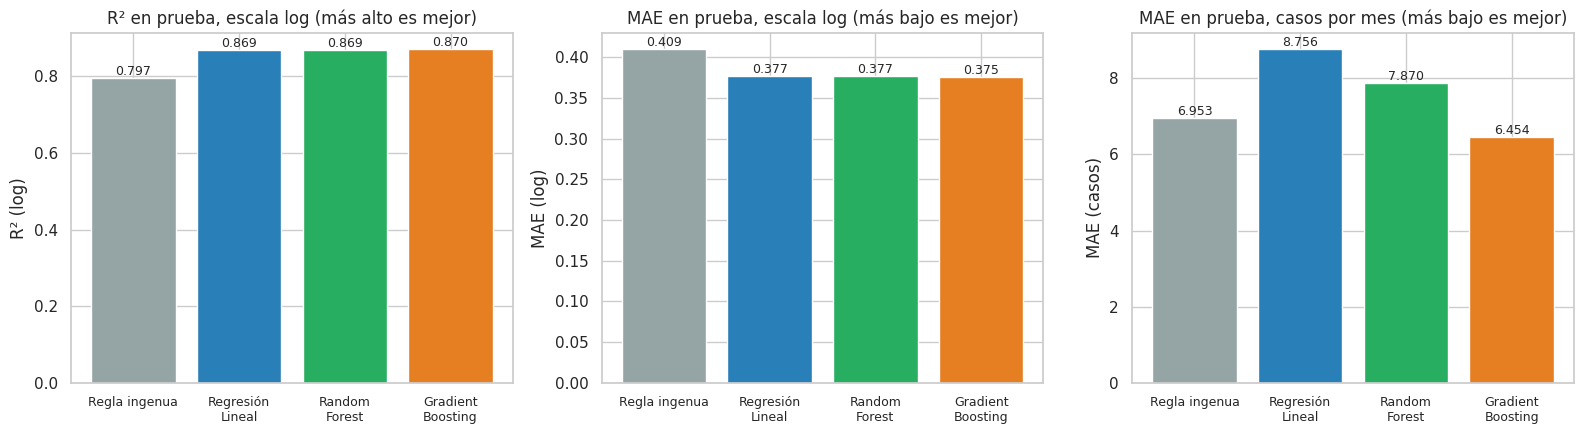

In [10]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
orden = zanahoria_2026_df_metricas.index
colores = ["#95a5a6", "#2980b9", "#27ae60", "#e67e22"]
for ax, col, titulo in zip(ejes, ["R² (log)", "MAE (log)", "MAE (casos)"],
                           ["R² en prueba, escala log (más alto es mejor)", "MAE en prueba, escala log (más bajo es mejor)", "MAE en prueba, casos por mes (más bajo es mejor)"]):
    ax.bar(range(len(orden)), zanahoria_2026_df_metricas[col], color=colores)
    ax.set_xticks(range(len(orden)))
    ax.set_xticklabels([o.replace(" (mes anterior)", "\n(mes anterior)").replace("Regla ingenua", "Regla\ningenua").replace(" ", "\n", 1) if "ingenua" not in o else o.replace("Regla ingenua (mes anterior)", "Regla ingenua") for o in orden], fontsize=9)
    ax.set(title=titulo, ylabel=col)
    for i, v in enumerate(zanahoria_2026_df_metricas[col]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_comparacion_metricas.png", dpi=130)
plt.show()

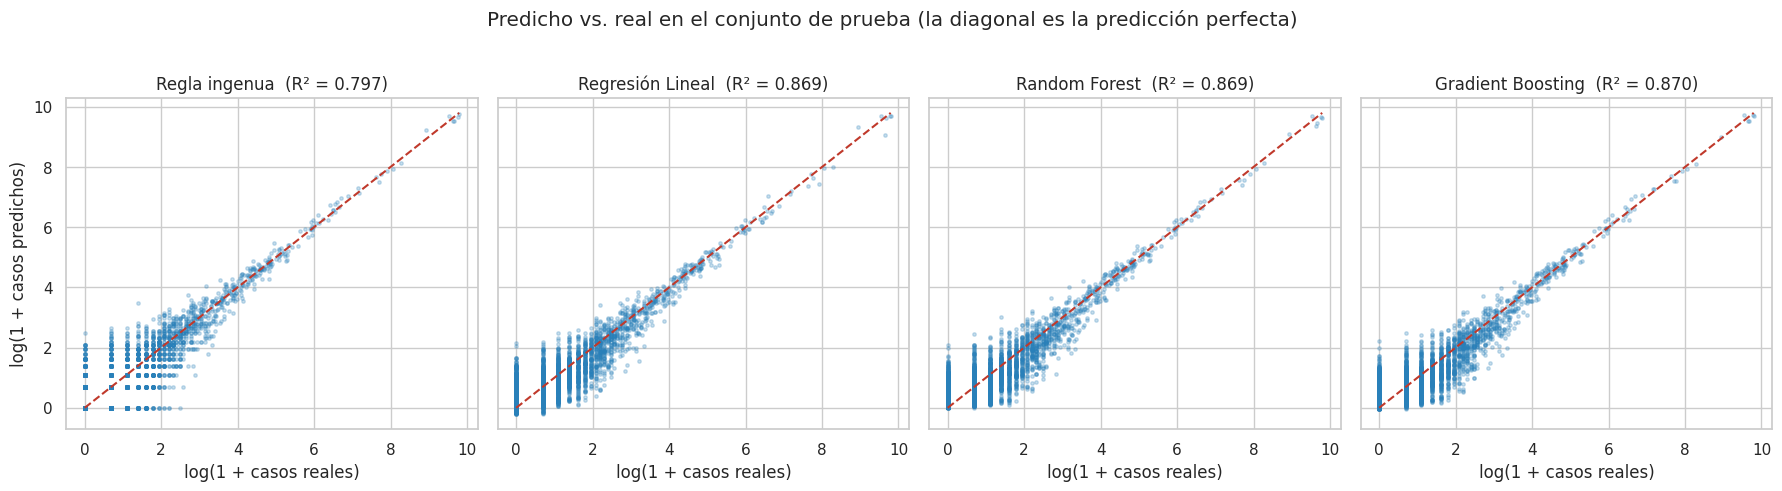

In [11]:
# Predicho vs. real en el conjunto de prueba (escala log para que se vean todos los municipios)
predicciones = {"Regla ingenua": pred_ingenua_log, "Regresión Lineal": pred_lineal, "Random Forest": pred_rf, "Gradient Boosting": pred_gb}
fig, ejes = plt.subplots(1, 4, figsize=(18, 4.8), sharex=True, sharey=True)
for ax, (nombre, pred) in zip(ejes, predicciones.items()):
    ax.scatter(y_test, pred, s=6, alpha=0.25, color="#2980b9")
    lim = [0, max(y_test.max(), np.max(pred))]
    ax.plot(lim, lim, color="#c0392b", ls="--")
    ax.set(title=f"{nombre}  (R² = {r2_score(y_test, pred):.3f})", xlabel="log(1 + casos reales)")
ejes[0].set_ylabel("log(1 + casos predichos)")
plt.suptitle("Predicho vs. real en el conjunto de prueba (la diagonal es la predicción perfecta)", y=1.02)
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_predicho_vs_real.png", dpi=130, bbox_inches="tight")
plt.show()

In [12]:
# ¿Las diferencias son reales o ruido? Bootstrap (2 000 remuestreos) sobre el error absoluto del conjunto de prueba, en log
rng = np.random.default_rng(SEMILLA)
err_log = {"Regla ingenua": np.abs(y_test.values - pred_ingenua_log), "Regresión Lineal": np.abs(y_test.values - pred_lineal),
           "Random Forest": np.abs(y_test.values - pred_rf), "Gradient Boosting": np.abs(y_test.values - pred_gb)}
remuestras = rng.integers(0, len(y_test), size=(2000, len(y_test)))
def zanahoria_2026_ic_dif(a: str, b: str) -> tuple[float, float, float]:
    """ZANAHORIA_2026: diferencia de MAE (a - b) con intervalo de confianza del 95% por bootstrap."""
    d = err_log[a] - err_log[b]
    medias = d[remuestras].mean(axis=1)
    return d.mean(), *np.percentile(medias, [2.5, 97.5])
zanahoria_2026_df_ic = pd.DataFrame(
    [(f"{m} vs. regla ingenua", *zanahoria_2026_ic_dif(m, "Regla ingenua")) for m in ["Regresión Lineal", "Random Forest", "Gradient Boosting"]]
    + [("Gradient Boosting vs. Regresión Lineal", *zanahoria_2026_ic_dif("Gradient Boosting", "Regresión Lineal"))]
    + [("Gradient Boosting vs. Random Forest", *zanahoria_2026_ic_dif("Gradient Boosting", "Random Forest"))],
    columns=["comparación", "diferencia de MAE (log)", "IC95% inferior", "IC95% superior"]).set_index("comparación")
zanahoria_2026_df_ic   # negativo = el primero comete menos error; si el IC no cruza 0, la diferencia es real

,diferencia de MAE (log),IC95% inferior,IC95% superior
comparación,,,
Regresión Lineal vs. regla ingenua,-0.032,-0.044,-0.021
Random Forest vs. regla ingenua,-0.033,-0.044,-0.022
Gradient Boosting vs. regla ingenua,-0.034,-0.046,-0.023
Gradient Boosting vs. Regresión Lineal,-0.002,-0.006,0.002
Gradient Boosting vs. Random Forest,-0.002,-0.005,0.002


**Insight:** los tres modelos superan a la regla ingenua en escala log (R² ≈ 0,87 frente a 0,80 y error medio 0,375-0,377 frente a 0,409), y la mejora es real: el intervalo de confianza de la diferencia no incluye el cero. Entre los tres modelos **no hay diferencias significativas** (el intervalo de Gradient Boosting contra Regresión Lineal o Random Forest sí cruza el cero). En casos por mes, que pesa a las capitales, Gradient Boosting es el único que también supera la regla ingenua (R² 0,986 vs. 0,983; error medio 6,5 vs. 7,0 casos).

### 7.1 ¿Dónde acierta y dónde falla? Error por tamaño de municipio
Un R² alto global puede esconder que el modelo solo acierta en las ciudades grandes. Se mide el error
(en casos por mes) por tramos del valor real.

In [13]:
mejor_modelo_nombre = zanahoria_2026_df_metricas.drop(index="Regla ingenua (mes anterior)")["MAE (log)"].idxmin()
pred_mejor = {"Regresión Lineal": pred_lineal, "Random Forest": pred_rf, "Gradient Boosting": pred_gb}[mejor_modelo_nombre]
print("Mejor modelo según MAE en escala log:", mejor_modelo_nombre)

tramos = pd.cut(casos_test, bins=[-1, 0, 4, 19, 99, 10**6], labels=["0 casos", "1-4", "5-19", "20-99", "100 o más"])
err = pd.DataFrame({
    "tramo": tramos,
    "n": 1,
    "Regla ingenua": np.abs(casos_test - lag_test),
    mejor_modelo_nombre: np.abs(casos_test - np.clip(np.expm1(pred_mejor), 0, None)),
})
zanahoria_2026_df_error_tramo = err.groupby("tramo", observed=True).agg(filas=("n", "sum"), ingenua=("Regla ingenua", "mean"), modelo=(mejor_modelo_nombre, "mean"))
zanahoria_2026_df_error_tramo["mejora %"] = (1 - zanahoria_2026_df_error_tramo["modelo"] / zanahoria_2026_df_error_tramo["ingenua"]) * 100
zanahoria_2026_df_error_tramo.columns = ["filas de prueba", "MAE regla ingenua (casos)", f"MAE {mejor_modelo_nombre} (casos)", "mejora %"]
zanahoria_2026_df_error_tramo

Mejor modelo según MAE en escala log: Gradient Boosting


,filas de prueba,MAE regla ingenua (casos),MAE Gradient Boosting (casos),mejora %
tramo,,,,
0 casos,1256,0.567,0.504,11.149
1-4,1148,1.671,1.169,30.049
5-19,603,3.836,3.458,9.844
20-99,204,9.794,9.934,-1.428
100 o más,89,179.809,170.940,4.932


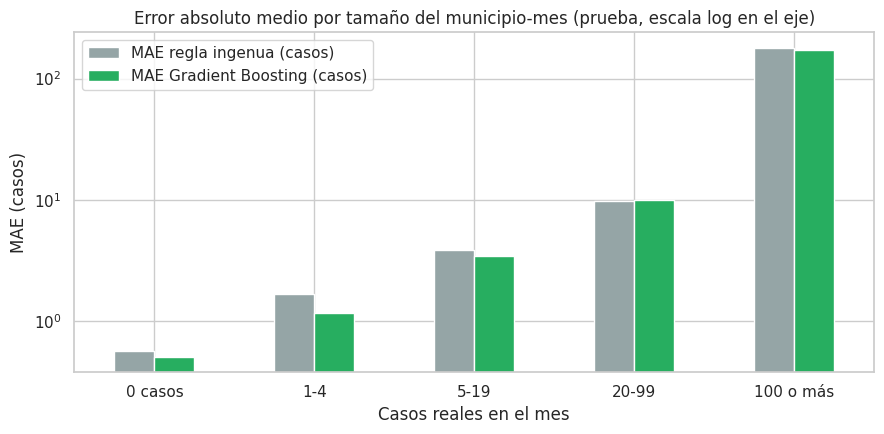

In [14]:
ax = zanahoria_2026_df_error_tramo[["MAE regla ingenua (casos)", f"MAE {mejor_modelo_nombre} (casos)"]].plot.bar(figsize=(9, 4.5), rot=0, color=["#95a5a6", "#27ae60"])
ax.set_yscale("log")
ax.set(title="Error absoluto medio por tamaño del municipio-mes (prueba, escala log en el eje)", xlabel="Casos reales en el mes", ylabel="MAE (casos)")
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_error_por_tramo.png", dpi=130)
plt.show()

**Insight:** la ganancia está en la **cola larga de municipios pequeños**: el error baja 30 % en municipios con 1 a 4 casos, 11 % en los que no tienen casos y 10 % en los de 5 a 19. En los de 20 a 99 casos el modelo empata con la regla ingenua (−1 %) y en los de 100 o más mejora 5 %. Para la gestión esto es valioso porque son cientos de municipios con poca capacidad instalada donde una buena proyección más ayuda; en las capitales el mes anterior ya es un buen estimador.

### 7.2 ¿Qué variables usa el mejor modelo?

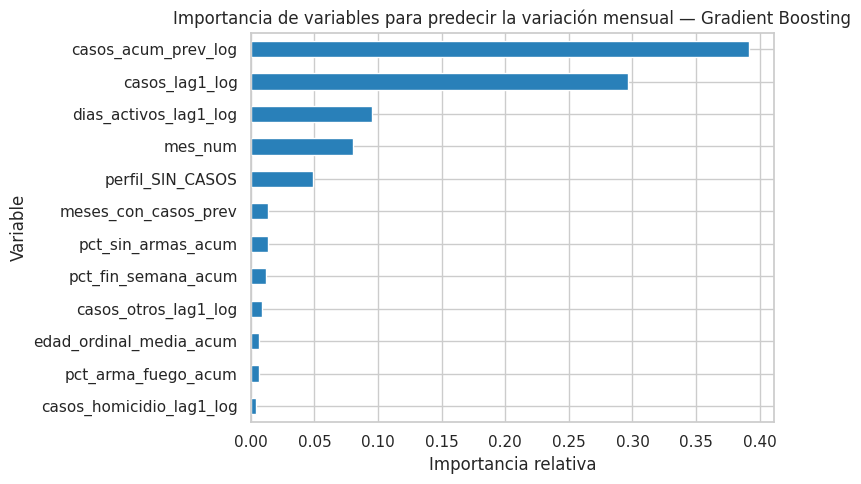

,importancia
casos_acum_prev_log,0.392
casos_lag1_log,0.296
dias_activos_lag1_log,0.096
mes_num,0.080
perfil_SIN_CASOS,0.049
meses_con_casos_prev,0.014
pct_sin_armas_acum,0.013
pct_fin_semana_acum,0.012
casos_otros_lag1_log,0.009
edad_ordinal_media_acum,0.006


In [15]:
if hasattr(dict(zip(["Regresión Lineal", "Random Forest", "Gradient Boosting"], [modelo_lineal, modelo_rf, modelo_gb]))[mejor_modelo_nombre], "feature_importances_"):
    imp = pd.Series(dict(zip(["Regresión Lineal", "Random Forest", "Gradient Boosting"], [modelo_lineal, modelo_rf, modelo_gb]))[mejor_modelo_nombre].feature_importances_, index=FEATURES)
else:
    imp = pd.Series(np.abs(modelo_lineal.coef_), index=FEATURES)
zanahoria_2026_importancias = imp.sort_values(ascending=False).head(12)
ax = zanahoria_2026_importancias[::-1].plot.barh(figsize=(8, 5), color="#2980b9")
ax.set(title=f"Importancia de variables para predecir la variación mensual — {mejor_modelo_nombre}", xlabel="Importancia relativa", ylabel="Variable")
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_importancia_variables.png", dpi=130)
plt.show()
zanahoria_2026_importancias.round(3).to_frame("importancia")

**Insight:** el modelo se apoya casi por completo en el **historial de actividad** del municipio: casos acumulados (39 %), casos del mes anterior (30 %) y días activos del mes anterior (10 %), más el mes del año (8 %). Las variables de perfil (género, tipo de arma, fin de semana, edad) pesan menos de 1,5 % cada una: cuánto delito hubo explica cuánto habrá, y *qué clase* de delito fue aporta casi nada. Conviene que lo sepa quien espere que el perfil de las víctimas mejore la proyección.

### 7.3 Robustez: validación temporal
La partición aleatoria mezcla meses. Para una proyección real lo honesto es **entrenar con el pasado y probar
con el futuro**: se entrena con febrero-septiembre y se prueba con octubre-diciembre. (Los modelos de árboles
no dependen de la escala, así que reutilizar las columnas escaladas de la Fase B no sesga esta comparación.)

In [16]:
entrena_t = zanahoria_2026_df_limpio["mes"] <= 9
X_tt, X_te = zanahoria_2026_df_limpio.loc[entrena_t, FEATURES], zanahoria_2026_df_limpio.loc[~entrena_t, FEATURES]
y_tt, y_te = zanahoria_2026_df_limpio.loc[entrena_t, "y_log1p"], zanahoria_2026_df_limpio.loc[~entrena_t, "y_log1p"]

base_tt = np.log1p(zanahoria_2026_df_limpio.loc[entrena_t, "casos_lag1_ref"])
base_te = np.log1p(zanahoria_2026_df_limpio.loc[~entrena_t, "casos_lag1_ref"])
filas_t = [zanahoria_2026_metricas(y_te, base_te.values, "Regla ingenua (mes anterior)")]
for nombre, modelo in {
    "Regresión Lineal": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=SEMILLA, n_jobs=-1, **busqueda_rf.best_params_),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEMILLA, **busqueda_gb.best_params_),
}.items():
    modelo.fit(X_tt, y_tt - base_tt)
    filas_t.append(zanahoria_2026_metricas(y_te, base_te.values + modelo.predict(X_te), nombre))
zanahoria_2026_df_metricas_temporal = pd.DataFrame(filas_t).set_index("modelo")
print(f"Entrenamiento: meses 2-9 ({entrena_t.sum():,} filas) | Prueba: meses 10-12 ({(~entrena_t).sum():,} filas)")
zanahoria_2026_df_metricas_temporal[["R² (log)", "MAE (log)", "R² (casos)", "MAE (casos)"]]

Entrenamiento: meses 2-9 (12,000 filas) | Prueba: meses 10-12 (4,500 filas)


,R² (log),MAE (log),R² (casos),MAE (casos)
modelo,,,,
Regla ingenua (mes anterior),0.798,0.405,0.863,6.207
Regresión Lineal,0.868,0.376,0.926,6.589
Random Forest,0.849,0.391,0.869,5.970
Gradient Boosting,0.855,0.378,0.899,5.734


In [17]:
sesgo = pd.DataFrame({
    "real": np.expm1(y_te).groupby(zanahoria_2026_df_limpio.loc[~entrena_t, "mes"]).sum(),
    "ingenua": zanahoria_2026_df_limpio.loc[~entrena_t].groupby("mes")["casos_lag1_ref"].sum(),
})
sesgo["ingenua vs real %"] = (sesgo["ingenua"] / sesgo["real"] - 1) * 100
sesgo

,real,ingenua,ingenua vs real %
mes,,,
10,"46,611.000",44205,-5.162
11,"36,786.000",46611,26.709
12,"30,872.000",36786,19.157


**Insight:** entrenando con el pasado (feb-sep) y probando con el futuro (oct-dic), los tres modelos siguen superando a la regla ingenua en escala log (error 0,376-0,391 vs. 0,405), y aquí la Regresión Lineal es la mejor; en casos por mes Gradient Boosting es el de menor error (5,7 vs. 6,2 de la regla ingenua). Se nota además el rezago de reporte: la regla ingenua sobreestima +27 % en noviembre y +19 % en diciembre porque los casos de esos meses se registraron de menos. Ningún modelo entrenado con meses anteriores puede anticiparlo, por lo que **las proyecciones de fin de año deben leerse como "casos que se registrarán", no como delito real**.

## 8. Modelo no supervisado — K-Means para segmentar municipios
El perfil anual de cada municipio (Fase B) se usa para agrupar municipios parecidos. El clustering no tiene
variable objetivo, así que no necesita partición. Se incluyen solo municipios con **30 o más casos al año**:
con menos casos un porcentaje (p. ej. "100 % mujeres") es puro azar de una o dos víctimas.

In [18]:
zanahoria_2026_df_perfil = pd.read_parquet(RAIZ / "datos" / "perfil_municipios.parquet")
vars_cluster = ["casos_log", "share_hurto", "share_vif", "share_homicidio", "pct_fin_semana", "pct_femenina", "pct_arma_fuego", "pct_sin_armas", "edad_ordinal_media"]

base_cl = zanahoria_2026_df_perfil[zanahoria_2026_df_perfil["casos"] >= 30].copy()
base_cl["casos_log"] = np.log1p(base_cl["casos"])
base_cl = base_cl.dropna(subset=vars_cluster).reset_index(drop=True)
print(f"Municipios con >= 30 casos: {len(base_cl)} de {len(zanahoria_2026_df_perfil)} ({base_cl['casos'].sum() / zanahoria_2026_df_perfil['casos'].sum():.1%} de los casos)")

# Estandarizar: K-Means usa distancias y las variables tienen escalas distintas
escalador_cl = StandardScaler()
X_cl = escalador_cl.fit_transform(base_cl[vars_cluster])

Municipios con >= 30 casos: 606 de 1500 (98.4% de los casos)


In [19]:
# Elección de k con Silhouette (más alto es mejor) y Davies-Bouldin (más bajo es mejor)
filas_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(X_cl)
    filas_k.append({"k": k, "Silhouette": silhouette_score(X_cl, km.labels_), "Davies-Bouldin": davies_bouldin_score(X_cl, km.labels_), "Inercia": km.inertia_})
zanahoria_2026_df_k = pd.DataFrame(filas_k).set_index("k")
zanahoria_2026_df_k

,Silhouette,Davies-Bouldin,Inercia
k,,,
2,0.240,1.560,"4,210.620"
3,0.207,1.528,"3,424.977"
4,0.189,1.518,"3,063.980"
5,0.190,1.472,"2,768.227"
6,0.192,1.545,"2,563.876"
7,0.181,1.482,"2,406.791"
8,0.182,1.471,"2,303.356"


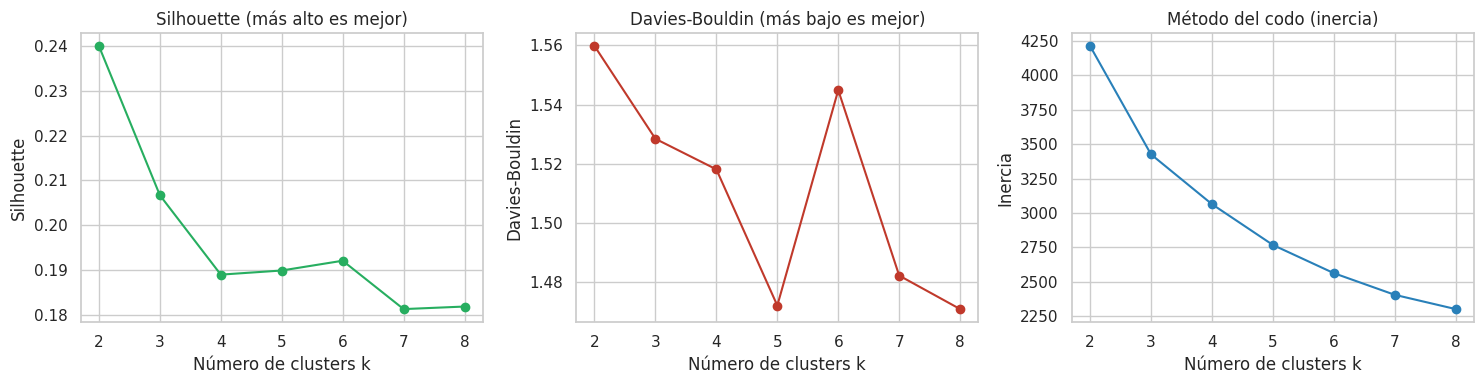

In [20]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].plot(zanahoria_2026_df_k.index, zanahoria_2026_df_k["Silhouette"], marker="o", color="#27ae60")
ejes[0].set(title="Silhouette (más alto es mejor)", xlabel="Número de clusters k", ylabel="Silhouette")
ejes[1].plot(zanahoria_2026_df_k.index, zanahoria_2026_df_k["Davies-Bouldin"], marker="o", color="#c0392b")
ejes[1].set(title="Davies-Bouldin (más bajo es mejor)", xlabel="Número de clusters k", ylabel="Davies-Bouldin")
ejes[2].plot(zanahoria_2026_df_k.index, zanahoria_2026_df_k["Inercia"], marker="o", color="#2980b9")
ejes[2].set(title="Método del codo (inercia)", xlabel="Número de clusters k", ylabel="Inercia")
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_seleccion_k.png", dpi=130)
plt.show()

In [21]:
# Silhouette es máximo en k=2, pero esa partición es una dicotomía burda. Regla: entre k >= 3, el k más pequeño
# cuyo Davies-Bouldin esté a menos de 0.01 del mejor (da segmentos accionables sin sobre-fragmentar).
db = zanahoria_2026_df_k.loc[3:, "Davies-Bouldin"]
K_FINAL = int(db[db <= db.min() + 0.01].index.min())
print("Silhouette máximo en k =", int(zanahoria_2026_df_k["Silhouette"].idxmax()), "| k elegido:", K_FINAL)
kmeans_final = KMeans(n_clusters=K_FINAL, n_init=50, random_state=SEMILLA).fit(X_cl)
base_cl["cluster"] = kmeans_final.labels_
print(f"Silhouette: {silhouette_score(X_cl, base_cl['cluster']):.3f} | Davies-Bouldin: {davies_bouldin_score(X_cl, base_cl['cluster']):.3f}")

zanahoria_2026_df_clusters = base_cl.groupby("cluster").agg(
    municipios=("dane", "size"), casos_totales=("casos", "sum"), casos_mediana=("casos", "median"),
    hurto=("share_hurto", "mean"), vif=("share_vif", "mean"), homicidio=("share_homicidio", "mean"),
    fin_semana=("pct_fin_semana", "mean"), mujeres=("pct_femenina", "mean"), arma_fuego=("pct_arma_fuego", "mean"), sin_armas=("pct_sin_armas", "mean"),
)
zanahoria_2026_df_clusters

Silhouette máximo en k = 2 | k elegido: 5
Silhouette: 0.190 | Davies-Bouldin: 1.479


,municipios,casos_totales,casos_mediana,hurto,vif,homicidio,fin_semana,mujeres,arma_fuego,sin_armas
cluster,,,,,,,,,,
0,159,22913,91.000,0.456,0.339,0.196,0.320,0.451,0.217,0.537
1,185,17979,58.000,0.314,0.577,0.106,0.335,0.589,0.085,0.712
2,62,4521,54.500,0.265,0.272,0.429,0.315,0.335,0.415,0.378
3,123,13170,80.000,0.580,0.323,0.087,0.407,0.479,0.076,0.743
4,77,413607,"1,310.000",0.624,0.322,0.053,0.305,0.520,0.117,0.666


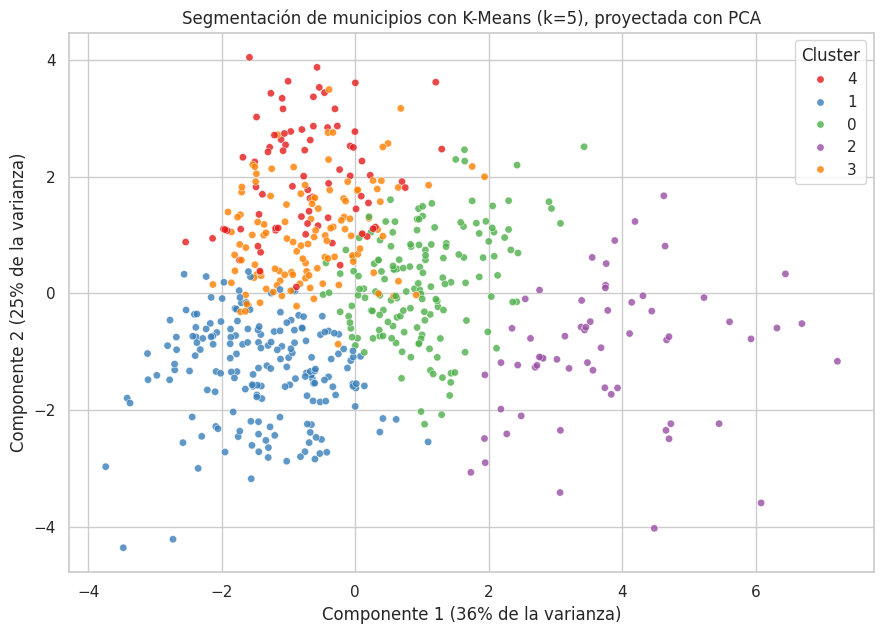

In [22]:
pca = PCA(n_components=2, random_state=SEMILLA)
coords = pca.fit_transform(X_cl)
fig, ax = plt.subplots(figsize=(9, 6.5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=base_cl["cluster"].astype(str), palette="Set1", s=28, alpha=0.8, ax=ax)
ax.set(title=f"Segmentación de municipios con K-Means (k={K_FINAL}), proyectada con PCA", xlabel=f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)", ylabel=f"Componente 2 ({pca.explained_variance_ratio_[1]:.0%} de la varianza)")
ax.legend(title="Cluster")
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_clusters_pca.png", dpi=130)
plt.show()

In [23]:
for c in sorted(base_cl["cluster"].unique()):
    top = base_cl[base_cl["cluster"] == c].nlargest(6, "casos")[["municipio", "departamento", "casos"]]
    print(f"Cluster {c}: " + "; ".join(f"{r.municipio.title()} ({r.casos:,})" for r in top.itertuples()))

Cluster 0: Buenaventura (961); Santander De Quilichao (774); Riohacha (750); Quibdó (673); Turbaco (582); Maicao (540)
Cluster 1: Apartadó (682); Caucasia (517); San Andres De Tumaco (514); Magangué (488); Barbosa (377); Turbo (365)
Cluster 2: Zona Bananera (288); Tibú (281); Villa Rica (166); Andes (163); Argelia (149); Remedios (131)
Cluster 3: Chiquinquirá (482); El Cerrito (344); Villa De San Diego De Ubate (322); Puerto Gaitán (306); Villeta (290); San Gil (274)
Cluster 4: Bogotá D.C. (179,963); Medellín (37,744); Cali (26,547); Barranquilla (14,277); Cartagena (10,366); Soacha (9,057)


**Insight:** con k = 5 aparecen segmentos con sentido de negocio: **(4) Grandes ciudades** (77 municipios, 86 % de los casos), **(1) municipios dominados por violencia intrafamiliar** (185; 58 % de sus casos, 59 % de víctimas mujeres, solo 8 % con arma de fuego), **(2) municipios de violencia armada** (62; 43 % homicidios y 41 % con arma de fuego, p. ej. Tibú y Zona Bananera), **(3) municipios de hurto** (123; 58 % hurto, mayor peso del fin de semana) y **(0) un grupo intermedio mixto** (159). Aun así la estructura es débil (Silhouette ≈ 0,19): los municipios forman más un continuo que grupos nítidos, así que los segmentos sirven para orientar la política, no como fronteras exactas.

## 9. Modelo elegido y justificación
#
**Modelo final: Gradient Boosting Regressor** (`n_estimators=300`, `max_depth=2`, `learning_rate=0.1`).

| Criterio | Regresión Lineal | Random Forest | Gradient Boosting |
|---|---|---|---|
| R² prueba (log) / MAE (log) | 0,869 / 0,377 | 0,869 / 0,377 | **0,870 / 0,375** |
| R² prueba (casos) / MAE (casos) | 0,949 / 8,76 | 0,971 / 7,87 | **0,986 / 6,45** |
| ¿Supera a la regla ingenua en casos? | No | No | **Sí** |
| Validación temporal (oct-dic), error en casos | 6,59 | 5,97 | **5,73** |
| Interpretabilidad | **Alta** | Media | Media |
| Simplicidad / costo | **Mayor** | Menor | Media |

**Por qué Gradient Boosting y no los otros:** (1) es el único que mejora a la regla ingenua en ambas escalas en la partición aleatoria y el de menor
error en casos en la validación temporal; (2) no sobreajusta (R² de entrenamiento 0,868 vs. 0,870 en prueba, a diferencia del
Random Forest, que pasa de 0,896 a 0,869); (3) con `max_depth=2` es un modelo poco complejo.

**Con honestidad:** en escala log las diferencias entre los tres **no son estadísticamente significativas**
(los intervalos de confianza cruzan el cero). Si la prioridad del cliente fuera **explicar** cada predicción a un
comité, la Regresión Lineal es una alternativa defendible: rinde casi igual en escala log y se audita coeficiente por coeficiente.
La decisión por Gradient Boosting se basa en que es el único que **no empeora** a las capitales.

**Efectividad y límites:** el modelo reduce el error medio ~8 % frente a la regla ingenua en escala log y 30 % en
municipios de 1 a 4 casos; en las capitales su aporte es marginal. Hay un solo año de datos y un rezago de
reporte en los últimos meses, así que el error real en 2026 puede ser mayor.

**Mejoras posibles:** (1) **más historia** (2022-2024) para capturar estacionalidad real y separarla del rezago;
(2) **población DANE** por municipio para trabajar con tasas por cada 100 mil habitantes; (3) variables de
calendario (festivos, quincenas, temporadas); (4) corregir el rezago de reporte con un factor de consolidación;
(5) modelos por segmento de tamaño (el clustering puede guiarlos); (6) probar otros algoritmos (HistGradientBoosting,
modelos de conteo Poisson/binomial negativa) y búsqueda de hiperparámetros más amplia.

*Nota sobre las métricas del enunciado:* matriz de confusión, accuracy y curva ROC aplican a clasificación; aquí
el problema es de **regresión**, por lo que las visualizaciones equivalentes son el gráfico predicho vs. real y el
error por tramo.